# BeeSafe AI — Phase 07: Robustness, Applicability Domain & Uncertainty Validation

**Purpose:** stress-test the selected toxicity classifier using the saved nested grouped out-of-fold (OOF) predictions, quantify uncertainty in performance estimates, examine performance across chemical-similarity strata, and evaluate calibration and threshold sensitivity.


## Cell 1 — Imports and reproducibility settings

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import os
import json
import hashlib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    average_precision_score, roc_auc_score, brier_score_loss, log_loss,
    precision_score, recall_score, f1_score, fbeta_score,
    balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
)
from sklearn.calibration import calibration_curve

RANDOM_STATE = 42
BOOTSTRAP_REPLICATES = int(os.environ.get("BEESAFE_P07_BOOTSTRAPS", "500"))
np.random.seed(RANDOM_STATE)
pd.set_option("display.max_columns", 80)
sns.set_theme(style="whitegrid")

print("BeeSafe AI — Phase 07: Robustness, Applicability Domain & Uncertainty")
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Group-bootstrap replicates:", BOOTSTRAP_REPLICATES)

BeeSafe AI — Phase 07: Robustness, Applicability Domain & Uncertainty
Pandas: 3.0.5
NumPy: 2.5.2
Group-bootstrap replicates: 500


## Cell 2 — Project paths and required artifacts

In [2]:
DEFAULT_ROOT = Path(r"E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI")
PROJECT_ROOT = Path(os.environ.get("BEESAFE_PROJECT_ROOT", str(DEFAULT_ROOT)))

PHASE03_DIR = PROJECT_ROOT / "data" / "processed" / "phase03"
PHASE05_DIR = PROJECT_ROOT / "reports" / "model_optimization_advanced"
PHASE06_DIR = PROJECT_ROOT / "reports" / "explainability_reliability"
REPORT_DIR = PROJECT_ROOT / "reports" / "robustness_validation_phase07"
FIGURE_DIR = REPORT_DIR / "figures"
TABLE_DIR = REPORT_DIR / "tables"

FEATURES_PATH = PHASE03_DIR / "03_baseline_features.npz"
METADATA_PATH = PHASE03_DIR / "03_baseline_metadata.csv"
OOF_PATH = PHASE05_DIR / "05_nested_cv_oof_predictions.csv"
FOLD_METRICS_PATH = PHASE05_DIR / "05_nested_cv_outer_fold_metrics.csv"
PHASE05_SUMMARY_PATH = PHASE05_DIR / "05_advanced_optimization_summary.json"
APPLICABILITY_PATH = PHASE06_DIR / "tables" / "06_oof_applicability_domain.csv"
PHASE06_METRICS_PATH = PHASE06_DIR / "06_nested_oof_metrics.json"

for folder in (REPORT_DIR, FIGURE_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

required = {
    "Phase 03 features": FEATURES_PATH,
    "Phase 03 metadata": METADATA_PATH,
    "Phase 05 nested OOF predictions": OOF_PATH,
    "Phase 05 outer-fold metrics": FOLD_METRICS_PATH,
    "Phase 06 OOF applicability-domain table": APPLICABILITY_PATH,
}
missing = [f"{name}: {path}" for name, path in required.items() if not path.is_file()]
if missing:
    raise FileNotFoundError(
        "Required prior-phase artifact(s) missing. Keep Phase 03–06 outputs and run prior phases first:\n- "
        + "\n- ".join(missing)
    )

print("Project root:", PROJECT_ROOT)
print("Output folder:", REPORT_DIR)
print("All required inputs exist.")

Project root: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI
Output folder: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\robustness_validation_phase07
All required inputs exist.


## Cell 3 — Load and integrity-check Phase 03–06 artifacts

In [3]:
with np.load(FEATURES_PATH, allow_pickle=False) as z:
    X_morgan = z["X_morgan"].astype(np.uint8, copy=True)
    y_features = z["y_binary"].astype(np.int64, copy=True)
    row_ids = z["source_row_index"].astype(np.int64, copy=True)

metadata = pd.read_csv(METADATA_PATH)
oof = pd.read_csv(OOF_PATH)
fold_metrics = pd.read_csv(FOLD_METRICS_PATH)
applicability = pd.read_csv(APPLICABILITY_PATH)
phase05_summary = json.loads(PHASE05_SUMMARY_PATH.read_text(encoding="utf-8")) if PHASE05_SUMMARY_PATH.exists() else {}
phase06_metrics = json.loads(PHASE06_METRICS_PATH.read_text(encoding="utf-8")) if PHASE06_METRICS_PATH.exists() else {}

required_meta = {"source_row_index", "name", "CID", "CAS", "SMILES", "label", "structure_group", "review_priority"}
required_oof = {"source_row_index", "outer_fold", "y_true", "oof_probability", "predicted_at_050", "predicted_at_oof_threshold"}
required_ad = {"source_row_index", "outer_fold", "max_tanimoto_to_outer_training"}
if required_meta - set(metadata.columns):
    raise ValueError(f"Phase 03 metadata missing columns: {sorted(required_meta - set(metadata.columns))}")
if required_oof - set(oof.columns):
    raise ValueError(f"Phase 05 OOF file missing columns: {sorted(required_oof - set(oof.columns))}")
if required_ad - set(applicability.columns):
    raise ValueError(f"Phase 06 applicability file missing columns: {sorted(required_ad - set(applicability.columns))}")

if len(row_ids) != len(metadata) or not np.array_equal(row_ids, metadata["source_row_index"].to_numpy(dtype=np.int64)):
    raise ValueError("Feature arrays and metadata do not align by source_row_index.")
if not np.array_equal(y_features, metadata["label"].to_numpy(dtype=int)):
    raise ValueError("Feature labels do not match metadata labels.")
if metadata["source_row_index"].duplicated().any():
    raise ValueError("Duplicate source_row_index values in metadata.")
if not metadata["review_priority"].astype(str).eq("NONE").all():
    raise ValueError("Phase 03 baseline contains review-flagged records; resolve Phase 03 policy before proceeding.")

for frame, name in [(oof, "OOF"), (applicability, "applicability")]:
    frame["source_row_index"] = frame["source_row_index"].astype(np.int64)
    frame["outer_fold"] = frame["outer_fold"].astype(int)
    if frame.duplicated(["source_row_index", "outer_fold"]).any():
        raise ValueError(f"Duplicate source_row_index/outer_fold pairs in {name} artifact.")

if oof["source_row_index"].duplicated().any():
    raise ValueError("Each OOF record should appear exactly once in the nested OOF file.")
if set(oof["source_row_index"]) != set(metadata["source_row_index"]):
    raise ValueError("Nested OOF record IDs do not exactly match Phase 03 baseline metadata.")
if not np.isfinite(oof["oof_probability"].to_numpy(dtype=float)).all():
    raise ValueError("OOF probabilities contain NaN/inf values.")
if ((oof["oof_probability"] < 0) | (oof["oof_probability"] > 1)).any():
    raise ValueError("OOF probabilities must lie in [0, 1].")

print("Phase 03 records:", len(metadata))
print("Nested OOF records:", len(oof))
print("Outer folds:", sorted(oof["outer_fold"].unique().tolist()))
print("Morgan fingerprint matrix:", X_morgan.shape)
print("Flagged records included in baseline:", int((metadata["review_priority"].astype(str) != "NONE").sum()))
print("Inputs passed initial integrity checks.")

Phase 03 records: 1025
Nested OOF records: 1025
Outer folds: [1, 2, 3, 4]
Morgan fingerprint matrix: (1025, 2048)
Flagged records included in baseline: 0
Inputs passed initial integrity checks.


## Cell 4 — Assemble aligned OOF table and verify grouped-fold integrity

In [4]:
meta_cols = metadata[["source_row_index", "name", "CID", "CAS", "SMILES", "label", "structure_group"]].copy()
oof = oof.merge(meta_cols, on="source_row_index", how="left", suffixes=("_oof", "_meta"), validate="one_to_one")
# Phase 05 may already carry name/CID columns. Prefer authoritative Phase 03 metadata after matching row IDs.
for col in ("name", "CID", "CAS", "SMILES", "label", "structure_group"):
    meta_col = f"{col}_meta"
    if meta_col in oof.columns:
        oof[col] = oof[meta_col]
if not np.array_equal(oof["y_true"].to_numpy(dtype=int), oof["label"].to_numpy(dtype=int)):
    raise ValueError("OOF target labels do not match Phase 03 labels.")

# Every structure_group should belong to only one outer validation fold.
group_fold_counts = oof.groupby("structure_group")["outer_fold"].nunique()
leaking_groups = group_fold_counts[group_fold_counts > 1]
if len(leaking_groups):
    print("WARNING: structure groups appear in multiple OOF folds:", len(leaking_groups))
else:
    print("Grouped-fold check passed: each structure_group appears in one outer validation fold.")

fold_integrity = oof.groupby("outer_fold").agg(
    records=("source_row_index", "size"),
    toxic_records=("y_true", "sum"),
    distinct_structure_groups=("structure_group", "nunique"),
    mean_predicted_probability=("oof_probability", "mean"),
).reset_index()
fold_integrity.to_csv(TABLE_DIR / "07_outer_fold_integrity.csv", index=False, encoding="utf-8-sig")
display(fold_integrity.round(4))

Grouped-fold check passed: each structure_group appears in one outer validation fold.


,outer_fold,records,toxic_records,distinct_structure_groups,mean_predicted_probability
0,1,256,73,83,0.4078
1,2,256,74,163,0.2417
2,3,257,74,165,0.3542
3,4,256,73,155,0.3501


## Cell 5 — Overall nested OOF performance and threshold comparison

In [5]:
y_true = oof["y_true"].to_numpy(dtype=int)
prob = oof["oof_probability"].to_numpy(dtype=float)
pred_050 = oof["predicted_at_050"].to_numpy(dtype=int)
pred_selected = oof["predicted_at_oof_threshold"].to_numpy(dtype=int)

def safe_auc(fn, y_true, values):
    try:
        return float(fn(y_true, values)) if len(np.unique(y_true)) == 2 else np.nan
    except Exception:
        return np.nan

def classification_metrics(y_true, pred):
    return {
        "precision_toxic": precision_score(y_true, pred, zero_division=0),
        "recall_toxic": recall_score(y_true, pred, zero_division=0),
        "f1_toxic": f1_score(y_true, pred, zero_division=0),
        "f2_toxic": fbeta_score(y_true, pred, beta=2, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "mcc": matthews_corrcoef(y_true, pred),
        "specificity_non_toxic": recall_score(1-y_true, 1-pred, zero_division=0),
    }

probability_metrics = {
    "n_records": int(len(y_true)),
    "positive_prevalence": float(np.mean(y_true)),
    "average_precision": safe_auc(average_precision_score, y_true, prob),
    "roc_auc": safe_auc(roc_auc_score, y_true, prob),
    "brier_score": brier_score_loss(y_true, prob),
    "log_loss": log_loss(y_true, np.clip(prob, 1e-8, 1-1e-8), labels=[0,1]),
}
rows = []
for rule, pred in [("threshold_0.50", pred_050), ("outer_training_oof_selected_threshold", pred_selected)]:
    rows.append({"threshold_rule": rule, **classification_metrics(y_true, pred)})
threshold_comparison = pd.DataFrame(rows)
print("Nested OOF probability metrics:")
display(pd.DataFrame([probability_metrics]).round(4))
print("Threshold-dependent metrics:")
display(threshold_comparison.round(4))

pd.DataFrame([probability_metrics]).to_csv(TABLE_DIR / "07_overall_oof_probability_metrics.csv", index=False, encoding="utf-8-sig")
threshold_comparison.to_csv(TABLE_DIR / "07_threshold_comparison.csv", index=False, encoding="utf-8-sig")

Nested OOF probability metrics:


,n_records,positive_prevalence,average_precision,roc_auc,brier_score,log_loss
0,1025,0.2868,0.7391,0.8174,0.1358,0.4362


Threshold-dependent metrics:


,threshold_rule,precision_toxic,recall_toxic,f1_toxic,f2_toxic,balanced_accuracy,mcc,specificity_non_toxic
0,threshold_0.50,0.7778,0.5952,0.6744,0.6246,0.7634,0.5757,0.9316
1,outer_training_oof_selected_threshold,0.4354,0.8027,0.5646,0.6868,0.6921,0.3480,0.5814


## Cell 6 — Fold-to-fold stability

,outer_fold,n,prevalence,average_precision,roc_auc,brier_score,recall_at_050,recall_at_selected_threshold,precision_at_selected_threshold
0,1,256,0.2852,0.8428,0.8994,0.1174,0.7671,0.9178,0.4379
1,2,256,0.2891,0.7332,0.7843,0.1449,0.4459,0.6757,0.5747
2,3,257,0.2879,0.6417,0.7376,0.1581,0.5000,0.7027,0.3662
3,4,256,0.2852,0.8017,0.8492,0.1228,0.6712,0.9178,0.4188


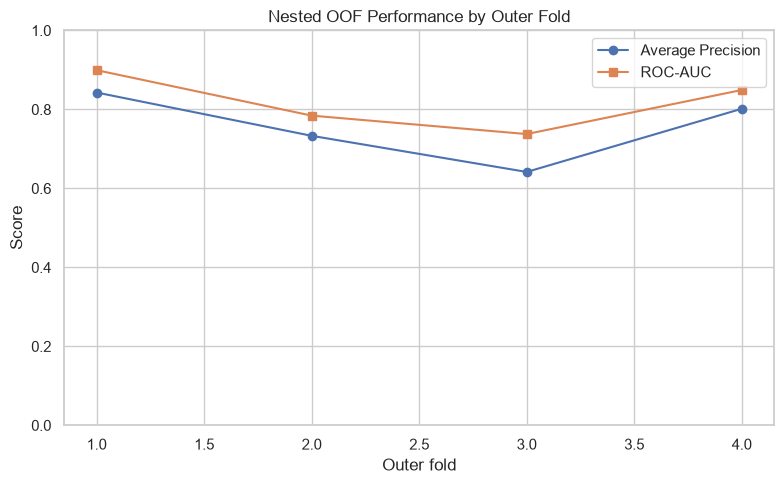

In [6]:
fold_rows = []
for fold, part in oof.groupby("outer_fold", sort=True):
    yt = part["y_true"].to_numpy(dtype=int)
    pp = part["oof_probability"].to_numpy(dtype=float)
    p50 = part["predicted_at_050"].to_numpy(dtype=int)
    psel = part["predicted_at_oof_threshold"].to_numpy(dtype=int)
    fold_rows.append({
        "outer_fold": int(fold), "n": len(part), "prevalence": float(yt.mean()),
        "average_precision": safe_auc(average_precision_score, yt, pp),
        "roc_auc": safe_auc(roc_auc_score, yt, pp),
        "brier_score": brier_score_loss(yt, pp),
        "recall_at_050": recall_score(yt, p50, zero_division=0),
        "recall_at_selected_threshold": recall_score(yt, psel, zero_division=0),
        "precision_at_selected_threshold": precision_score(yt, psel, zero_division=0),
    })
fold_stability = pd.DataFrame(fold_rows)
display(fold_stability.round(4))
fold_stability.to_csv(TABLE_DIR / "07_fold_stability.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fold_stability["outer_fold"], fold_stability["average_precision"], marker="o", label="Average Precision")
ax.plot(fold_stability["outer_fold"], fold_stability["roc_auc"], marker="s", label="ROC-AUC")
ax.set_ylim(0, 1)
ax.set_xlabel("Outer fold")
ax.set_ylabel("Score")
ax.set_title("Nested OOF Performance by Outer Fold")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_fold_performance_stability.png", dpi=250, bbox_inches="tight")
plt.show()

## Cell 7 — Group bootstrap confidence intervals for OOF metrics

In [7]:
# Resample whole structure_group clusters (not individual rows) to retain within-group dependence.
rng = np.random.default_rng(RANDOM_STATE)
group_to_indices = {g: idx.to_numpy() for g, idx in oof.groupby("structure_group").groups.items()}
unique_groups = np.array(list(group_to_indices.keys()), dtype=object)
bootstrap_rows = []
for b in range(BOOTSTRAP_REPLICATES):
    sampled_groups = rng.choice(unique_groups, size=len(unique_groups), replace=True)
    sampled_idx_parts = [group_to_indices[g] for g in sampled_groups]
    idx = np.concatenate(sampled_idx_parts) if sampled_idx_parts else np.array([], dtype=int)
    if len(idx) == 0:
        continue
    yt = y_true[idx]
    if len(np.unique(yt)) < 2:
        continue
    pr = prob[idx]
    bootstrap_rows.append({
        "replicate": b,
        "average_precision": average_precision_score(yt, pr),
        "roc_auc": roc_auc_score(yt, pr),
        "brier_score": brier_score_loss(yt, pr),
    })
bootstrap_df = pd.DataFrame(bootstrap_rows)
if bootstrap_df.empty:
    raise RuntimeError("No valid group-bootstrap replicates. Check group and label distributions.")
ci_rows = []
for metric in ["average_precision", "roc_auc", "brier_score"]:
    vals = bootstrap_df[metric].dropna().to_numpy()
    ci_rows.append({
        "metric": metric,
        "oof_point_estimate": probability_metrics["average_precision"] if metric == "average_precision" else probability_metrics["roc_auc"] if metric == "roc_auc" else probability_metrics["brier_score"],
        "bootstrap_2.5_percentile": float(np.quantile(vals, 0.025)),
        "bootstrap_97.5_percentile": float(np.quantile(vals, 0.975)),
        "valid_replicates": len(vals),
        "structure_groups": len(unique_groups),
    })
bootstrap_ci = pd.DataFrame(ci_rows)
display(bootstrap_ci.round(4))
bootstrap_df.to_csv(TABLE_DIR / "07_group_bootstrap_replicates.csv", index=False, encoding="utf-8-sig")
bootstrap_ci.to_csv(TABLE_DIR / "07_group_bootstrap_confidence_intervals.csv", index=False, encoding="utf-8-sig")
print("Interpretation: these are cluster-bootstrap intervals for the saved OOF sample, not a substitute for external validation.")

,metric,oof_point_estimate,bootstrap_2.5_percentile,bootstrap_97.5_percentile,valid_replicates,structure_groups
0,average_precision,0.7391,0.6444,0.8068,500,566
1,roc_auc,0.8174,0.7552,0.8636,500,566
2,brier_score,0.1358,0.1218,0.1552,500,566


Interpretation: these are cluster-bootstrap intervals for the saved OOF sample, not a substitute for external validation.


## Cell 8 — Join Phase 06 applicability-domain similarity

,max_tanimoto_to_outer_training
count,1025.0000
mean,0.3960
std,0.1523
min,0.0000
25%,0.2778
50%,0.3788
75%,0.5000
max,1.0000


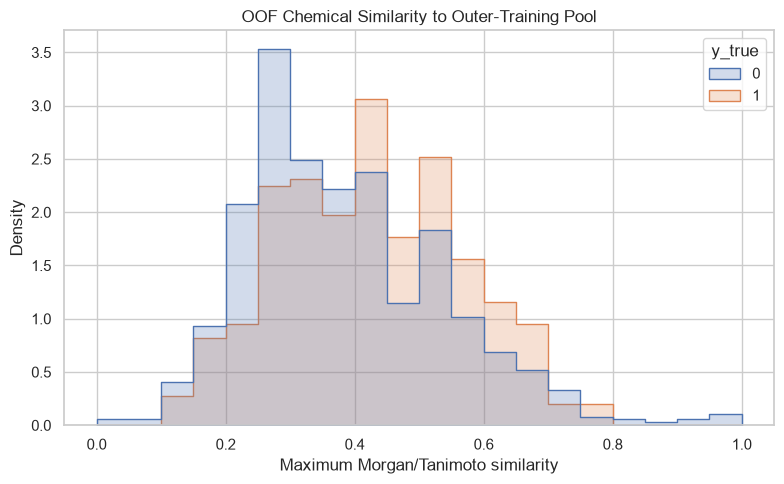

In [8]:
# Match on both record ID and outer fold so the similarity corresponds to the proper outer-training pool.
ad_cols = ["source_row_index", "outer_fold", "max_tanimoto_to_outer_training"]
if "nearest_training_CID" in applicability.columns:
    ad_cols += ["nearest_training_CID", "nearest_training_name", "nearest_training_label"]
if applicability.duplicated(["source_row_index", "outer_fold"]).any():
    raise ValueError("Applicability-domain file has duplicate record/fold keys.")

oof = oof.merge(applicability[ad_cols], on=["source_row_index", "outer_fold"], how="left", validate="one_to_one")
if oof["max_tanimoto_to_outer_training"].isna().any():
    raise ValueError("Some OOF records lack a corresponding applicability-domain similarity value.")
if not oof["max_tanimoto_to_outer_training"].between(0, 1).all():
    raise ValueError("Tanimoto similarity values must be within [0, 1].")

sim_summary = oof["max_tanimoto_to_outer_training"].describe().to_frame("max_tanimoto_to_outer_training")
display(sim_summary.round(4))
sim_summary.to_csv(TABLE_DIR / "07_applicability_similarity_summary.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(data=oof, x="max_tanimoto_to_outer_training", hue="y_true", bins=20, element="step", stat="density", common_norm=False, ax=ax)
ax.set_title("OOF Chemical Similarity to Outer-Training Pool")
ax.set_xlabel("Maximum Morgan/Tanimoto similarity")
ax.set_ylabel("Density")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_applicability_similarity_distribution.png", dpi=250, bbox_inches="tight")
plt.show()

## Cell 9 — Performance by chemical-similarity quartile

,similarity_quartile,records,mean_max_similarity,toxic_prevalence,average_precision,roc_auc,brier_score,toxic_recall_at_fold_threshold,toxic_precision_at_fold_threshold,misclassification_rate_at_fold_threshold
0,Q2,256,0.3263,0.2695,0.7634,0.8452,0.1286,0.8696,0.4255,0.3516
1,Q3,256,0.4339,0.3477,0.8447,0.8729,0.1231,0.8539,0.5390,0.3047
2,Q1 lowest similarity,257,0.2208,0.1829,0.2534,0.5698,0.1652,0.5745,0.1957,0.5097
3,Q4 highest similarity,256,0.6035,0.3477,0.8115,0.8648,0.1262,0.8202,0.5984,0.2539


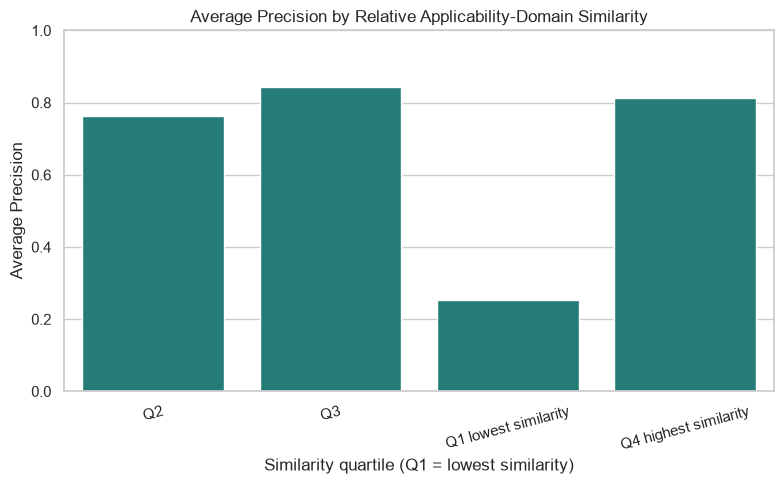

In [9]:
# Quartiles are data-relative descriptive groups, not externally validated applicability cutoffs.
oof["similarity_quartile"] = pd.qcut(
    oof["max_tanimoto_to_outer_training"].rank(method="first"),
    q=4, labels=["Q1 lowest similarity", "Q2", "Q3", "Q4 highest similarity"]
)
quartile_rows = []
for q, part in oof.groupby("similarity_quartile", observed=False, sort=False):
    yt = part["y_true"].to_numpy(dtype=int)
    pp = part["oof_probability"].to_numpy(dtype=float)
    pred = part["predicted_at_oof_threshold"].to_numpy(dtype=int)
    quartile_rows.append({
        "similarity_quartile": str(q), "records": len(part),
        "mean_max_similarity": part["max_tanimoto_to_outer_training"].mean(),
        "toxic_prevalence": yt.mean(),
        "average_precision": safe_auc(average_precision_score, yt, pp),
        "roc_auc": safe_auc(roc_auc_score, yt, pp),
        "brier_score": brier_score_loss(yt, pp),
        "toxic_recall_at_fold_threshold": recall_score(yt, pred, zero_division=0),
        "toxic_precision_at_fold_threshold": precision_score(yt, pred, zero_division=0),
        "misclassification_rate_at_fold_threshold": np.mean(yt != pred),
    })
quartile_results = pd.DataFrame(quartile_rows)
display(quartile_results.round(4))
quartile_results.to_csv(TABLE_DIR / "07_performance_by_similarity_quartile.csv", index=False, encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=quartile_results, x="similarity_quartile", y="average_precision", ax=ax, color="#178A83")
ax.set_ylim(0, 1)
ax.set_title("Average Precision by Relative Applicability-Domain Similarity")
ax.set_xlabel("Similarity quartile (Q1 = lowest similarity)")
ax.set_ylabel("Average Precision")
ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_performance_by_similarity_quartile.png", dpi=250, bbox_inches="tight")
plt.show()

## Cell 10 — Calibration and confidence-bin error analysis

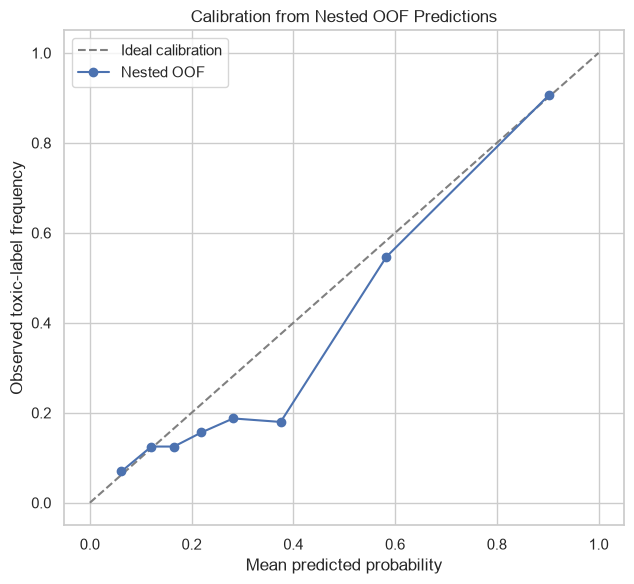

,probability_bin,records,mean_predicted_probability,observed_toxic_frequency,mean_similarity,absolute_calibration_gap
0,0,129,0.0622,0.0698,0.4065,0.0076
1,1,128,0.1210,0.1250,0.4097,0.0040
2,2,128,0.1654,0.1250,0.4133,0.0404
3,3,128,0.2192,0.1562,0.3767,0.0629
4,4,128,0.2817,0.1875,0.3335,0.0942
5,5,128,0.3751,0.1797,0.3602,0.1954
6,6,128,0.5830,0.5469,0.3885,0.0362
7,7,128,0.9024,0.9062,0.4793,0.0038


Quantile-bin expected calibration error (ECE): 0.0555
ECE depends on binning and is a descriptive summary, not a formal guarantee.


In [10]:
# Calibration: compare average predicted probability with observed positive frequency.
prob_true, prob_pred = calibration_curve(y_true, prob, n_bins=8, strategy="quantile")
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Ideal calibration")
ax.plot(prob_pred, prob_true, marker="o", label="Nested OOF")
ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Observed toxic-label frequency")
ax.set_title("Calibration from Nested OOF Predictions")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_oof_calibration_curve.png", dpi=250, bbox_inches="tight")
plt.show()

calibration_df = oof[["source_row_index", "y_true", "oof_probability", "max_tanimoto_to_outer_training"]].copy()
calibration_df["probability_bin"] = pd.qcut(calibration_df["oof_probability"].rank(method="first"), q=8, labels=False)
calibration_bins = calibration_df.groupby("probability_bin", observed=False).agg(
    records=("y_true", "size"), mean_predicted_probability=("oof_probability", "mean"),
    observed_toxic_frequency=("y_true", "mean"), mean_similarity=("max_tanimoto_to_outer_training", "mean")
).reset_index()
calibration_bins["absolute_calibration_gap"] = (calibration_bins["mean_predicted_probability"] - calibration_bins["observed_toxic_frequency"]).abs()
display(calibration_bins.round(4))
calibration_bins.to_csv(TABLE_DIR / "07_probability_calibration_bins.csv", index=False, encoding="utf-8-sig")

# Simple expected calibration error using these quantile bins; descriptive and binning-dependent.
ece = float(np.average(calibration_bins["absolute_calibration_gap"], weights=calibration_bins["records"]))
print("Quantile-bin expected calibration error (ECE):", round(ece, 4))
print("ECE depends on binning and is a descriptive summary, not a formal guarantee.")

## Cell 11 — Selective prediction: what if we defer low-similarity cases?

,minimum_similarity_quantile,similarity_cutoff,records_retained,coverage,average_precision,roc_auc,brier_score,toxic_recall_at_fold_threshold,misclassification_rate_at_fold_threshold
0,0.00,0.0000,1025,1.0000,0.7391,0.8174,0.1358,0.8027,0.3551
1,0.25,0.2778,769,0.7502,0.8047,0.8610,0.1265,0.8427,0.3043
2,0.50,0.3788,515,0.5024,0.8220,0.8666,0.1250,0.8371,0.2816
3,0.75,0.5000,269,0.2624,0.8260,0.8691,0.1252,0.8247,0.2565


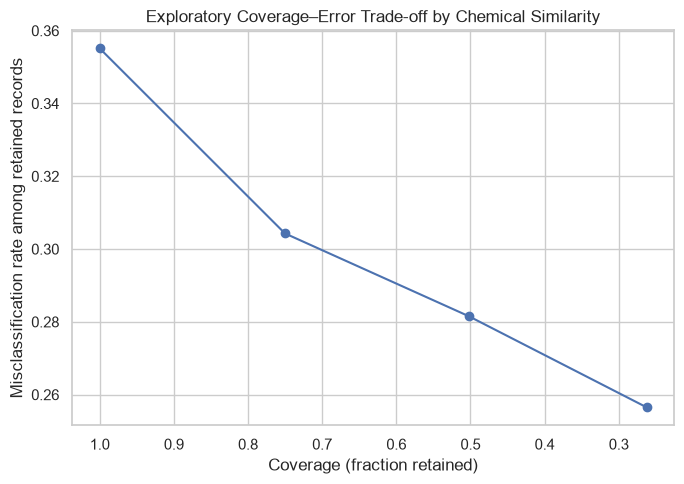

In [11]:
# Illustrative coverage-risk analysis. Similarity cutoffs are quantiles of this OOF sample,
# not universal chemical safety boundaries and must not be deployed as regulatory thresholds.
quantile_levels = [0.00, 0.25, 0.50, 0.75]
selective_rows = []
for q in quantile_levels:
    cutoff = float(oof["max_tanimoto_to_outer_training"].quantile(q))
    subset = oof[oof["max_tanimoto_to_outer_training"] >= cutoff]
    yt = subset["y_true"].to_numpy(dtype=int)
    pp = subset["oof_probability"].to_numpy(dtype=float)
    pred = subset["predicted_at_oof_threshold"].to_numpy(dtype=int)
    selective_rows.append({
        "minimum_similarity_quantile": q,
        "similarity_cutoff": cutoff,
        "records_retained": len(subset),
        "coverage": len(subset) / len(oof),
        "average_precision": safe_auc(average_precision_score, yt, pp),
        "roc_auc": safe_auc(roc_auc_score, yt, pp),
        "brier_score": brier_score_loss(yt, pp),
        "toxic_recall_at_fold_threshold": recall_score(yt, pred, zero_division=0),
        "misclassification_rate_at_fold_threshold": np.mean(yt != pred),
    })
selective_results = pd.DataFrame(selective_rows)
display(selective_results.round(4))
selective_results.to_csv(TABLE_DIR / "07_selective_prediction_coverage_risk.csv", index=False, encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(selective_results["coverage"], selective_results["misclassification_rate_at_fold_threshold"], marker="o")
ax.set_xlabel("Coverage (fraction retained)")
ax.set_ylabel("Misclassification rate among retained records")
ax.set_title("Exploratory Coverage–Error Trade-off by Chemical Similarity")
ax.invert_xaxis()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "07_selective_prediction_coverage_risk.png", dpi=250, bbox_inches="tight")
plt.show()

## Cell 12 — Robustness checks and error slices

In [12]:
# Compare errors across broad descriptive slices. No slice-specific cutoff is optimized here.
oof["threshold_error"] = (oof["y_true"].to_numpy(dtype=int) != oof["predicted_at_oof_threshold"].to_numpy(dtype=int)).astype(int)
oof["predicted_label_050"] = oof["predicted_at_050"].astype(int)
oof["predicted_label_selected"] = oof["predicted_at_oof_threshold"].astype(int)

# Per-fold confusion summary under both threshold rules.
err_rows = []
for fold, part in oof.groupby("outer_fold", sort=True):
    yt = part["y_true"].to_numpy(dtype=int)
    for rule, pred_col in [("0.50", "predicted_at_050"), ("fold-specific training OOF threshold", "predicted_at_oof_threshold")]:
        yp = part[pred_col].to_numpy(dtype=int)
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        err_rows.append({"outer_fold": int(fold), "threshold_rule": rule, "n": len(part), "tn": tn, "fp": fp, "fn": fn, "tp": tp,
                         "precision_toxic": precision_score(yt, yp, zero_division=0),
                         "recall_toxic": recall_score(yt, yp, zero_division=0),
                         "specificity": tn / (tn + fp) if tn + fp else np.nan,
                         "mcc": matthews_corrcoef(yt, yp)})
fold_error_slices = pd.DataFrame(err_rows)
display(fold_error_slices.round(4))
fold_error_slices.to_csv(TABLE_DIR / "07_error_slices_by_fold.csv", index=False, encoding="utf-8-sig")

# Most important misses / false alarms using cross-fitted OOF predictions.
review = oof.copy()
review["prediction_error_at_050"] = (review["y_true"] != review["predicted_at_050"]).astype(int)
review["prediction_error_at_fold_threshold"] = (review["y_true"] != review["predicted_at_oof_threshold"]).astype(int)
review["error_type_at_050"] = np.select(
    [(review["y_true"] == 1) & (review["predicted_at_050"] == 0),
     (review["y_true"] == 0) & (review["predicted_at_050"] == 1)],
    ["false_negative", "false_positive"], default="correct"
)
review["error_type_at_fold_threshold"] = np.select(
    [(review["y_true"] == 1) & (review["predicted_at_oof_threshold"] == 0),
     (review["y_true"] == 0) & (review["predicted_at_oof_threshold"] == 1)],
    ["false_negative", "false_positive"], default="correct"
)
cols = ["source_row_index", "name", "CID", "CAS", "SMILES", "structure_group", "outer_fold", "y_true", "oof_probability", "max_tanimoto_to_outer_training", "error_type_at_050", "error_type_at_fold_threshold"]
review[cols].to_csv(TABLE_DIR / "07_oof_error_review.csv", index=False, encoding="utf-8-sig")
print("Saved OOF error review table with cross-fitted predictions only.")

,outer_fold,threshold_rule,n,tn,fp,fn,tp,precision_toxic,recall_toxic,specificity,mcc
0,1,0.50,256,159,24,17,56,0.7000,0.7671,0.8689,0.6195
1,1,fold-specific training OOF threshold,256,97,86,6,67,0.4379,0.9178,0.5301,0.4124
2,2,0.50,256,180,2,41,33,0.9429,0.4459,0.9890,0.5739
3,2,fold-specific training OOF threshold,256,145,37,24,50,0.5747,0.6757,0.7967,0.4521
4,3,0.50,257,177,6,37,37,0.8605,0.5000,0.9672,0.5668
5,3,fold-specific training OOF threshold,257,93,90,22,52,0.3662,0.7027,0.5082,0.1921
6,4,0.50,256,165,18,24,49,0.7313,0.6712,0.9016,0.5884
7,4,fold-specific training OOF threshold,256,90,93,6,67,0.4188,0.9178,0.4918,0.3820


Saved OOF error review table with cross-fitted predictions only.


## Cell 13 — Save final Phase 07 summary and integrity manifest

In [13]:
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

outputs = sorted(str(p.relative_to(PROJECT_ROOT)) for p in REPORT_DIR.rglob("*") if p.is_file())
summary = {
    "project": "BeeSafe AI",
    "phase": "07 — Robustness, Applicability Domain & Uncertainty Validation",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "n_records": int(len(oof)),
    "n_structure_groups": int(oof["structure_group"].nunique()),
    "outer_folds": sorted(int(v) for v in oof["outer_fold"].unique()),
    "grouped_fold_integrity_passed": bool(len(leaking_groups) == 0),
    "nested_oof_metrics": probability_metrics,
    "threshold_metrics": threshold_comparison.to_dict(orient="records"),
    "group_bootstrap_confidence_intervals": bootstrap_ci.to_dict(orient="records"),
    "similarity_quartile_results": quartile_results.to_dict(orient="records"),
    "selective_prediction_results": selective_results.to_dict(orient="records"),
    "quantile_bin_ece": ece,
    "bootstrap_replicates_requested": BOOTSTRAP_REPLICATES,
    "bootstrap_replicates_valid": int(len(bootstrap_df)),
    "limitations": [
        "Performance derives from saved nested grouped OOF predictions and the existing dataset, not an external prospective test.",
        "Cluster-bootstrap intervals are descriptive and depend on the grouping and bootstrap design.",
        "Applicability-domain quartiles are relative to this dataset; no universal similarity cutoff is asserted.",
        "Probability calibration is dataset-specific and should not be interpreted as a guarantee for new chemicals.",
        "Tree disagreement from Phase 06 is not a calibrated predictive interval and is not used here as validated uncertainty.",
        "Predictions concern ApisTox dataset-defined honeybee toxicity labels, not field-level ecological harm or regulatory safety.",
    ],
}
summary_path = REPORT_DIR / "07_robustness_validation_summary.json"
summary_path.write_text(json.dumps(summary, indent=2, default=lambda x: float(x) if isinstance(x, (np.floating,)) else int(x) if isinstance(x, (np.integer,)) else str(x)), encoding="utf-8")

input_files = [FEATURES_PATH, METADATA_PATH, OOF_PATH, FOLD_METRICS_PATH, APPLICABILITY_PATH]
manifest = {
    "project": "BeeSafe AI",
    "phase": "07",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "inputs": {str(p.relative_to(PROJECT_ROOT)): sha256_file(p) for p in input_files},
    "outputs": sorted(str(p.relative_to(PROJECT_ROOT)) for p in REPORT_DIR.rglob("*") if p.is_file()),
}
(REPORT_DIR / "07_reproducibility_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print("=" * 62)
print("BEESAFE AI — PHASE 07 COMPLETED")
print("=" * 62)
print("Records assessed:", len(oof))
print("Grouped fold integrity:", "PASS" if len(leaking_groups) == 0 else "REVIEW REQUIRED")
print("Nested OOF Average Precision:", round(probability_metrics["average_precision"], 4))
print("Nested OOF ROC-AUC:", round(probability_metrics["roc_auc"], 4))
print("Brier score:", round(probability_metrics["brier_score"], 4))
print("Group-bootstrap valid replicates:", len(bootstrap_df))
print("Summary:", summary_path)
print("Outputs saved to:", REPORT_DIR)

BEESAFE AI — PHASE 07 COMPLETED
Records assessed: 1025
Grouped fold integrity: PASS
Nested OOF Average Precision: 0.7391
Nested OOF ROC-AUC: 0.8174
Brier score: 0.1358
Group-bootstrap valid replicates: 500
Summary: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\robustness_validation_phase07\07_robustness_validation_summary.json
Outputs saved to: E:\CODE\Python\ALL Project\Machine Learning\BeeSafe AI\reports\robustness_validation_phase07


## How to interpret Phase 07

This phase does **not** train a new model or tune against a new holdout. It stress-tests existing nested OOF predictions. Read the following in order:
1. **Fold stability** — are scores consistent across outer folds?
2. **Group-bootstrap intervals** — how variable are the metrics under resampling whole structure groups?
3. **Similarity quartiles and selective coverage** — does performance change for compounds less similar to the outer-training chemistry?
4. **Calibration** — do predicted probabilities agree with observed label frequency on the OOF sample?
5. **Error slices** — where do false positives and false negatives occur?

No similarity quartile or threshold in this notebook is a universal toxicological cutoff. A final scientific claim still requires external/prospective validation on independent chemical records.